# Построение модели кредитного скоринга

### Часть 1. Импорт библиотек

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score, f1_score, roc_curve, precision_recall_curve, auc)
import xgboost as xgb
import lightgbm as lgb
import catboost as cb
import shap

# Библиотеки для Задачи 3 (Survival Analysis)
from lifelines import KaplanMeierFitter, CoxPHFitter

%matplotlib inline
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 12

import warnings
warnings.filterwarnings('ignore')

### Часть 2. Загрузка данных

In [19]:
app = pd.read_csv('application_record.csv')
crd = pd.read_csv('credit_record.csv')

print(f"Application shape: {app.shape}")
print(f"Credit record shape: {crd.shape}")

Application shape: (438557, 18)
Credit record shape: (1048575, 3)


### Часть 3. EDA

Анализ категориальных признаков

In [20]:
categorical_cols = [
    'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY',
    'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE',
    'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE'
]

for col in categorical_cols:
    print(app[col].value_counts())

CODE_GENDER
F    294440
M    144117
Name: count, dtype: int64
FLAG_OWN_CAR
N    275459
Y    163098
Name: count, dtype: int64
FLAG_OWN_REALTY
Y    304074
N    134483
Name: count, dtype: int64
NAME_INCOME_TYPE
Working                 226104
Commercial associate    100757
Pensioner                75493
State servant            36186
Student                     17
Name: count, dtype: int64
NAME_EDUCATION_TYPE
Secondary / secondary special    301821
Higher education                 117522
Incomplete higher                 14851
Lower secondary                    4051
Academic degree                     312
Name: count, dtype: int64
NAME_FAMILY_STATUS
Married                 299828
Single / not married     55271
Civil marriage           36532
Separated                27251
Widow                    19675
Name: count, dtype: int64
NAME_HOUSING_TYPE
House / apartment      393831
With parents            19077
Municipal apartment     14214
Rented apartment         5974
Office apartment         39

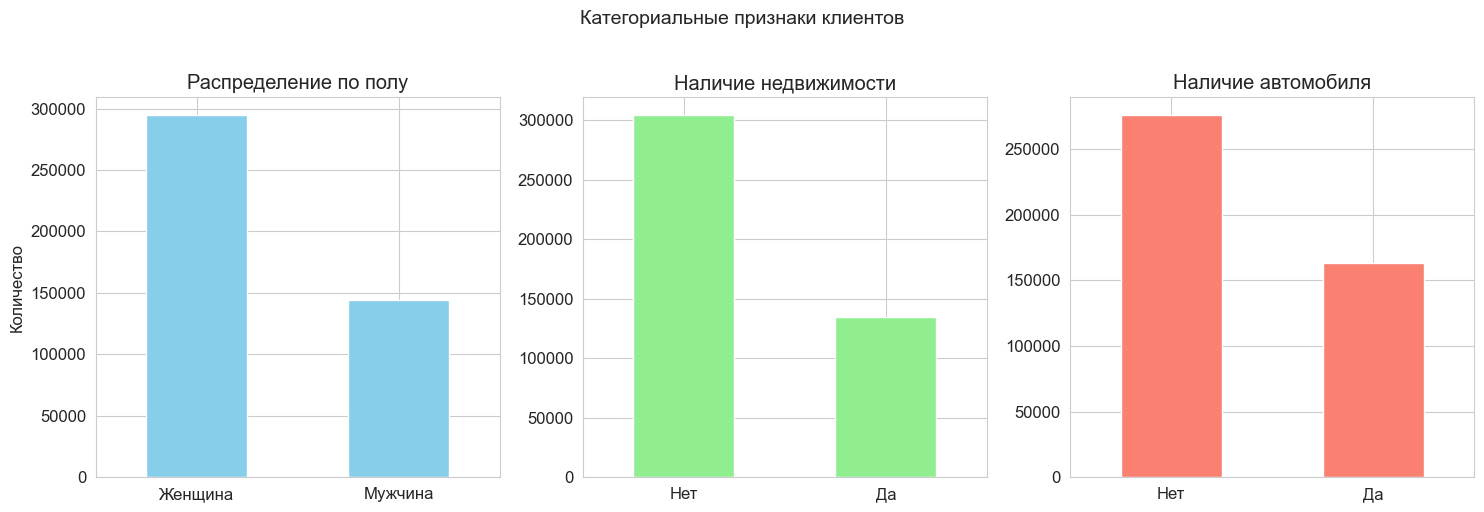

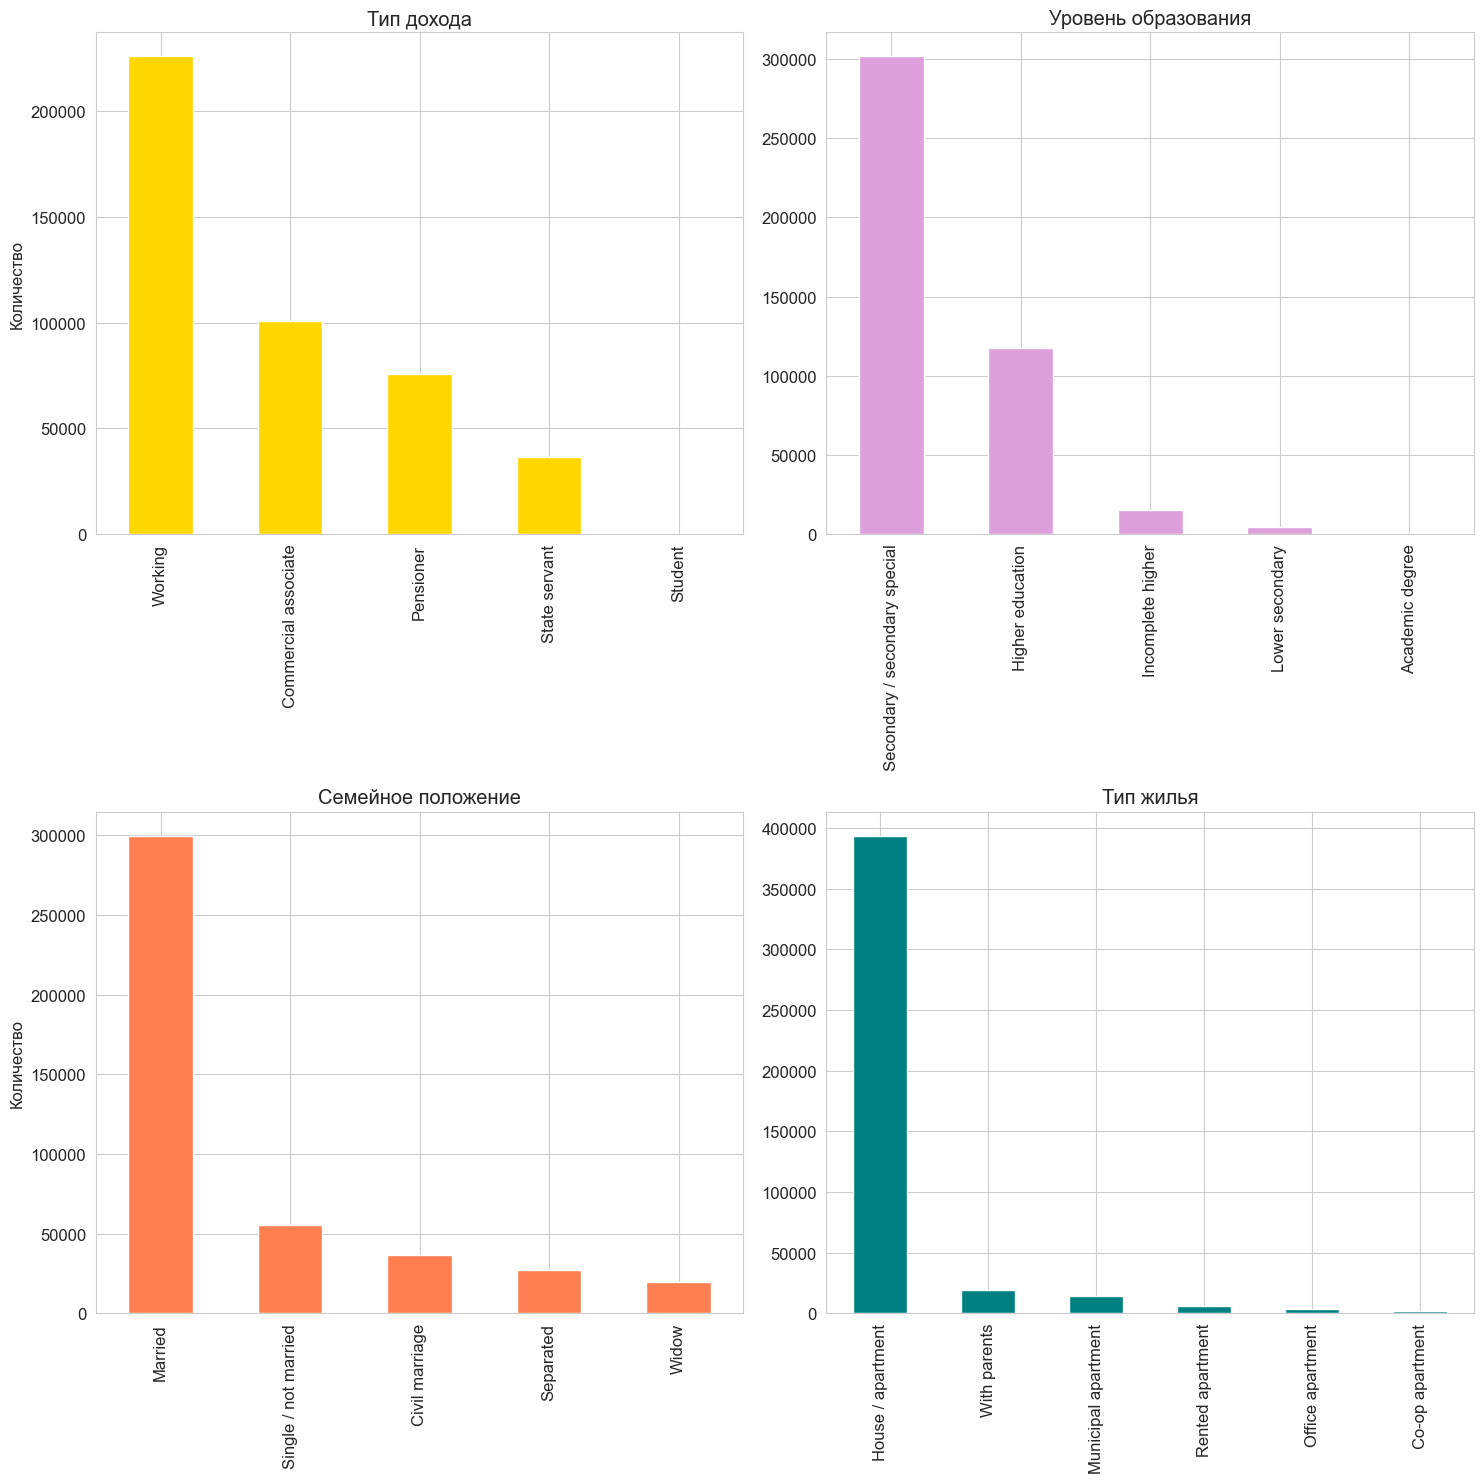

In [21]:
fig1, axes1 = plt.subplots(1, 3, figsize=(15, 5))

# Пол
app['CODE_GENDER'].value_counts().plot(kind='bar', ax=axes1[0], color='skyblue')
axes1[0].set_title('Распределение по полу')
axes1[0].set_xlabel('')
axes1[0].set_ylabel('Количество')
axes1[0].set_xticklabels(['Женщина', 'Мужчина'], rotation=0)

# Наличие недвижимости
app['FLAG_OWN_REALTY'].value_counts().plot(kind='bar', ax=axes1[1], color='lightgreen')
axes1[1].set_title('Наличие недвижимости')
axes1[1].set_xlabel('')
axes1[1].set_ylabel('')
axes1[1].set_xticklabels(['Нет', 'Да'], rotation=0)

# Наличие автомобиля
app['FLAG_OWN_CAR'].value_counts().plot(kind='bar', ax=axes1[2], color='salmon')
axes1[2].set_title('Наличие автомобиля')
axes1[2].set_xlabel('')
axes1[2].set_ylabel('')
axes1[2].set_xticklabels(['Нет', 'Да'], rotation=0)

plt.suptitle('Категориальные признаки клиентов', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

fig2, axes2 = plt.subplots(2, 2, figsize=(15, 15))

# Тип дохода
app['NAME_INCOME_TYPE'].value_counts().plot(kind='bar', ax=axes2[0,0], color='gold')
axes2[0,0].set_title('Тип дохода')
axes2[0,0].set_xlabel('')
axes2[0,0].set_ylabel('Количество')

# Уровень образования
app['NAME_EDUCATION_TYPE'].value_counts().plot(kind='bar', ax=axes2[0,1], color='plum')
axes2[0,1].set_title('Уровень образования')
axes2[0,1].set_xlabel('')
axes2[0,1].set_ylabel('')

# Семейное положение
app['NAME_FAMILY_STATUS'].value_counts().plot(kind='bar', ax=axes2[1,0], color='coral')
axes2[1,0].set_title('Семейное положение')
axes2[1,0].set_xlabel('')
axes2[1,0].set_ylabel('Количество')

# Тип жилья
app['NAME_HOUSING_TYPE'].value_counts().plot(kind='bar', ax=axes2[1,1], color='teal')
axes2[1,1].set_title('Тип жилья')
axes2[1,1].set_xlabel('')
axes2[1,1].set_ylabel('')

plt.tight_layout()
plt.show()

#OCCUPATION_TYPE - не рассматриваем, т.к. много вариантов профессий

Анализ числовых признаков

Возраст: от 20 до 69, средний: 43.3
Стаж: от 0 до 48, средний: 5.5


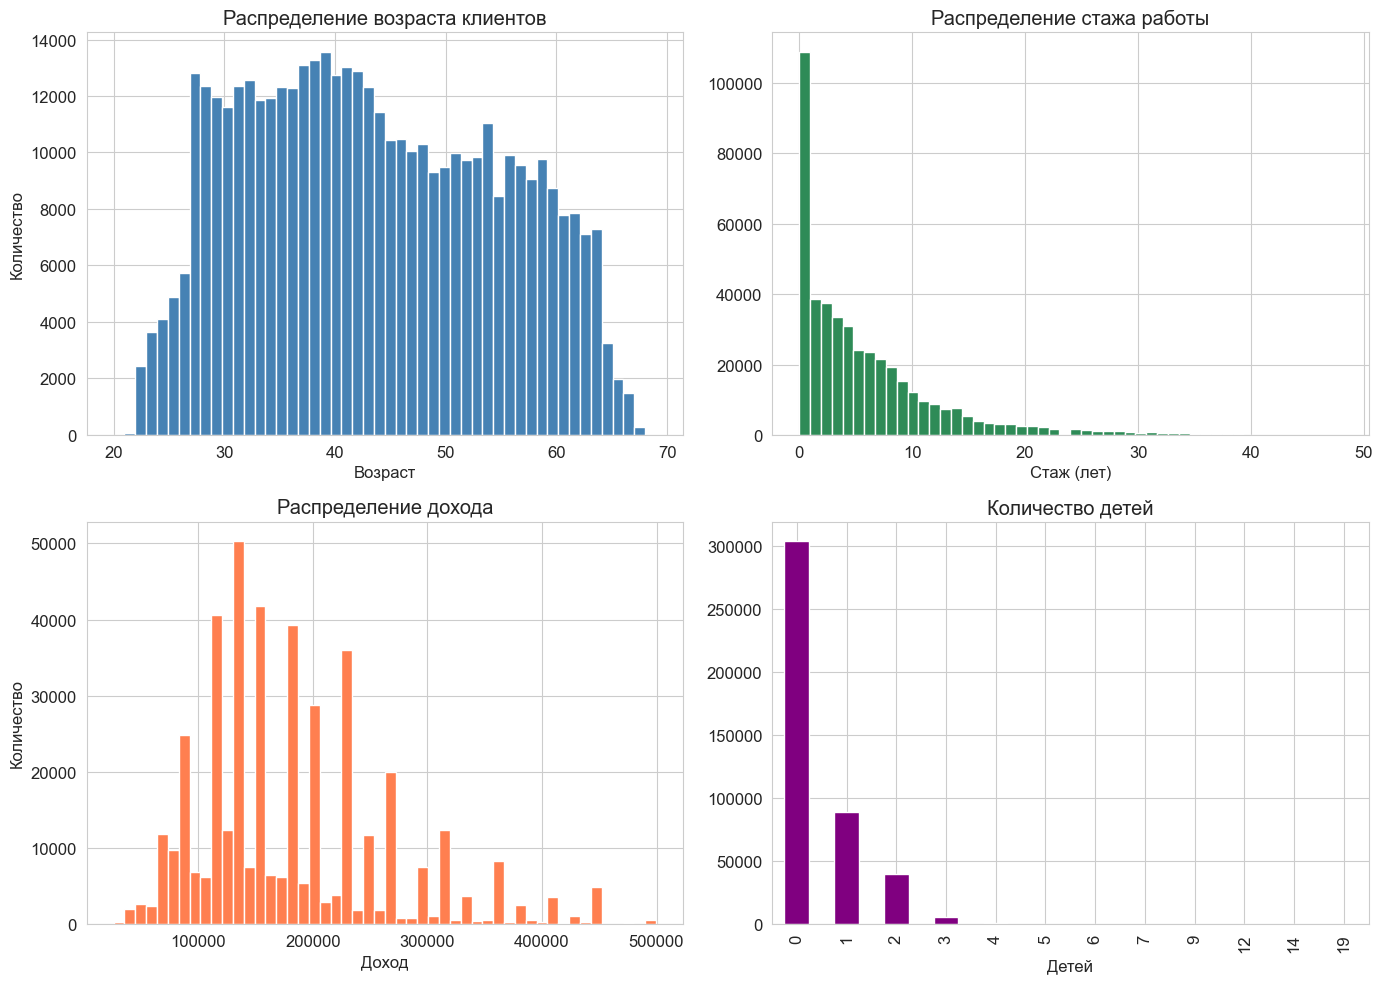

In [22]:
# Возраст
app['AGE'] = -app['DAYS_BIRTH'] // 365
print(f"Возраст: от {app['AGE'].min()} до {app['AGE'].max()}, средний: {app['AGE'].mean():.1f}")

# Стаж работы
app['WORK_EXPERIENCE'] = app['DAYS_EMPLOYED'].apply(lambda x: -x//365 if x < 0 else 0)
print(f"Стаж: от {app['WORK_EXPERIENCE'].min()} до {app['WORK_EXPERIENCE'].max()}, средний: {app['WORK_EXPERIENCE'].mean():.1f}")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Возраст
axes[0,0].hist(app['AGE'], bins=50, color='steelblue')
axes[0,0].set_title('Распределение возраста клиентов')
axes[0,0].set_xlabel('Возраст')
axes[0,0].set_ylabel('Количество')

# Стаж работы
axes[0,1].hist(app['WORK_EXPERIENCE'], bins=50, color='seagreen')
axes[0,1].set_title('Распределение стажа работы')
axes[0,1].set_xlabel('Стаж (лет)')
axes[0,1].set_ylabel('')

# Доход (ограничим до 500000 для наглядности)
filtered = app[app['AMT_INCOME_TOTAL'] < 500000]['AMT_INCOME_TOTAL']
axes[1,0].hist(filtered, bins=50, color='coral')
axes[1,0].set_title('Распределение дохода')
axes[1,0].set_xlabel('Доход')
axes[1,0].set_ylabel('Количество')

# Количество детей
app['CNT_CHILDREN'].value_counts().sort_index().plot(kind='bar', ax=axes[1,1], color='purple')
axes[1,1].set_title('Количество детей')
axes[1,1].set_xlabel('Детей')
axes[1,1].set_ylabel('')

plt.tight_layout()
plt.show()

Проверка дисперсии флагов

In [23]:
flag_cols = ['FLAG_MOBIL', 'FLAG_WORK_PHONE', 'FLAG_PHONE', 'FLAG_EMAIL']
for col in flag_cols:
    unique_values = app[col].nunique()
    print(f"{col}: {unique_values} значений, распределение: {app[col].value_counts().to_dict()}")

FLAG_MOBIL: 1 значений, распределение: {1: 438557}
FLAG_WORK_PHONE: 2 значений, распределение: {0: 348156, 1: 90401}
FLAG_PHONE: 2 значений, распределение: {0: 312353, 1: 126204}
FLAG_EMAIL: 2 значений, распределение: {0: 391102, 1: 47455}


Корреляционный анализ

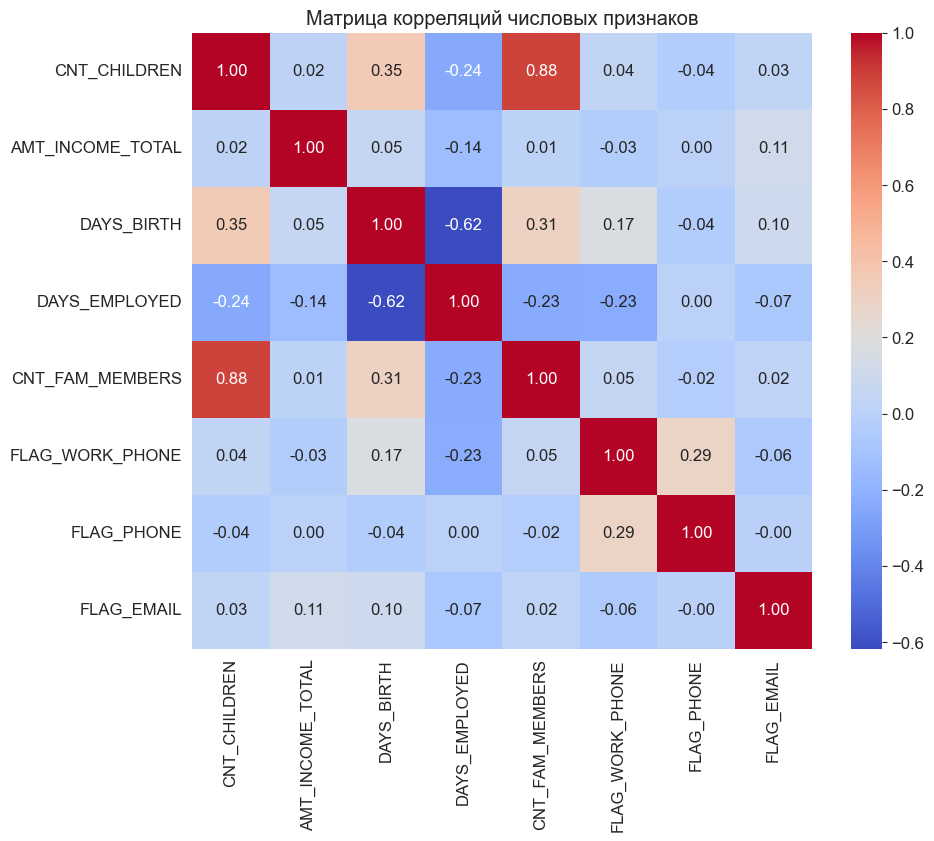

In [24]:
numeric_for_corr = ['CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'CNT_FAM_MEMBERS', 'FLAG_WORK_PHONE', 'FLAG_PHONE', 'FLAG_EMAIL']
# FLAG_MOBIL не используем, т.к. значение всегда = True
plt.figure(figsize=(10, 8))
corr_matrix = app[numeric_for_corr].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Матрица корреляций числовых признаков')
plt.show()

### Часть 3. FEATURE ENGINEERING

Очистка аномалий

In [25]:
# Удаление дубликатов по ID
app = app.drop_duplicates(subset=['ID'], keep='first')

# Расчет возраста и фильтрация аномалий
app['AGE'] = -app['DAYS_BIRTH'] // 365
app = app[(app['AGE'] >= 18) & (app['AGE'] <= 100)]

# Обработка аномалий стажа (DAYS_EMPLOYED > 0 означает безработный/пенсионер)
app['IS_UNEMPLOYED'] = (app['DAYS_EMPLOYED'] > 0).astype(int)
app.loc[app['DAYS_EMPLOYED'] > 0, 'DAYS_EMPLOYED'] = 0
app['WORK_EXPERIENCE'] = -app['DAYS_EMPLOYED'] // 365

# Удаление константного признака FLAG_MOBIL (у всех равен 1)
if 'FLAG_MOBIL' in app.columns:
    app = app.drop(columns=['FLAG_MOBIL'])

print(f"Размер таблицы анкет после очистки: {app.shape}")

Размер таблицы анкет после очистки: (438510, 20)


Подготовка признаков

In [26]:
# Создание новых финансовых и демографических признаков
app['INCOME_PER_PERSON'] = app['AMT_INCOME_TOTAL'] / (app['CNT_FAM_MEMBERS'] + 1)
app['CHILD_RATIO'] = app['CNT_CHILDREN'] / (app['CNT_FAM_MEMBERS'] + 1)
app['HAS_PHONE'] = ((app['FLAG_WORK_PHONE'] == 1) | (app['FLAG_PHONE'] == 1)).astype(int)

# Подготовка целевой переменной по правилу просрочки 60+ дней (статусы 2, 3, 4, 5)
crd['IS_DEFAULT'] = crd['STATUS'].isin(['2', '3', '4', '5']).astype(int)
credit_target = crd.groupby('ID')['IS_DEFAULT'].max().reset_index()
credit_target.columns = ['ID', 'HAS_DEFAULT']

# Объединение таблиц
df = app.merge(credit_target, on='ID', how='inner')

# Выделение категориальных признаков для One-Hot Encoding
categorical_cols = [
    'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_INCOME_TYPE',
    'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE'
]

# Кодирование
df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# Определение списков признаков
exclude_cols = ['ID', 'HAS_DEFAULT', 'DAYS_BIRTH', 'DAYS_EMPLOYED']
feature_cols = [col for col in df.columns if col not in exclude_cols]

X = df[feature_cols]
y = df['HAS_DEFAULT']

# Разделение на train/test со стратификацией
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Масштабирование признаков
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Размер выборки: {X.shape}")
print(f"Дисбаланс классов: \n{y.value_counts(normalize=True)}")

Размер выборки: (36457, 49)
Дисбаланс классов: 
HAS_DEFAULT
0    0.983103
1    0.016897
Name: proportion, dtype: float64


### Часть 4. ML

Функция для расчета кредитных метрик

In [27]:
def calculate_ks_statistic(y_true, y_proba):
    """Функция для расчета статистики Колмогорова-Смирнова (KS)"""
    df_ks = pd.DataFrame({'real': y_true, 'proba': y_proba})
    df_ks = df_ks.sort_values(by='proba', ascending=False)
    df_ks['good'] = 1 - df_ks['real']
    df_ks['bad'] = df_ks['real']
    df_ks['cum_good'] = df_ks['good'].cumsum() / df_ks['good'].sum()
    df_ks['cum_bad'] = df_ks['bad'].cumsum() / df_ks['bad'].sum()
    ks_stat = max(abs(df_ks['cum_good'] - df_ks['cum_bad']))
    return ks_stat

def evaluate_scoring_model(model_name, y_true, y_pred, y_proba):
    """Вывод комплексной оценки скоринговой модели"""
    precision, recall, _ = precision_recall_curve(y_true, y_proba)
    pr_auc = auc(recall, precision)

    # Расчет Brier Score (погрешность вероятности)
    brier = np.mean((y_true - y_proba) ** 2)
    ks_stat = calculate_ks_statistic(y_true, y_proba)

    print(f"--- {model_name} ---")
    print(f"ROC-AUC (Разделяющая способность):    {roc_auc_score(y_true, y_proba):.4f}")
    print(f"PR-AUC (Качество при дисбалансе):     {pr_auc:.4f}")
    print(f"KS Statistic (Статистика КC):         {ks_stat:.4f}")
    print(f"Brier Score (Точность вероятности):   {brier:.4f}")
    print(f"Recall (Полнота по дефолтам):         {recall_score(y_true, y_pred):.4f}")
    print(f"Precision (Точность по дефолтам):      {precision_score(y_true, y_pred):.4f}\n")

    return float(roc_auc_score(y_true, y_proba))

# Расчет веса для несбалансированных классов
ratio = (len(y_train) - sum(y_train)) / sum(y_train)

# 1. Логистическая регрессия
lr = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr.fit(X_train_scaled, y_train)
evaluate_scoring_model("Logistic Regression", y_test, lr.predict(X_test_scaled), lr.predict_proba(X_test_scaled)[:, 1])

# 2. Random Forest
rf = RandomForestClassifier(n_estimators=150, class_weight='balanced', random_state=42, n_jobs=-1)
rf.fit(X_train_scaled, y_train)
evaluate_scoring_model("Random Forest", y_test, rf.predict(X_test_scaled), rf.predict_proba(X_test_scaled)[:, 1])

# 3. XGBoost
xgb_model = xgb.XGBClassifier(scale_pos_weight=ratio, random_state=42, eval_metric='logloss')
xgb_model.fit(X_train, y_train)
evaluate_scoring_model("XGBoost", y_test, xgb_model.predict(X_test), xgb_model.predict_proba(X_test)[:, 1])

# 4. LightGBM
lgb_model = lgb.LGBMClassifier(is_unbalance=True, random_state=42, verbose=-1)
lgb_model.fit(X_train, y_train)
evaluate_scoring_model("LightGBM", y_test, lgb_model.predict(X_test), lgb_model.predict_proba(X_test)[:, 1])

# 5. CatBoost
cb_model = cb.CatBoostClassifier(auto_class_weights='Balanced', random_state=42, verbose=0)
cb_model.fit(X_train, y_train)
evaluate_scoring_model("CatBoost", y_test, cb_model.predict(X_test), cb_model.predict_proba(X_test)[:, 1])

--- Logistic Regression ---
ROC-AUC (Разделяющая способность):    0.5710
PR-AUC (Качество при дисбалансе):     0.0687
KS Statistic (Статистика КC):         0.1446
Brier Score (Точность вероятности):   0.2302
Recall (Полнота по дефолтам):         0.4703
Precision (Точность по дефолтам):      0.0211

--- Random Forest ---
ROC-AUC (Разделяющая способность):    0.7705
PR-AUC (Качество при дисбалансе):     0.1485
KS Statistic (Статистика КC):         0.4687
Brier Score (Точность вероятности):   0.0227
Recall (Полнота по дефолтам):         0.3568
Precision (Точность по дефолтам):      0.1930

--- XGBoost ---
ROC-AUC (Разделяющая способность):    0.7002
PR-AUC (Качество при дисбалансе):     0.1525
KS Statistic (Статистика КC):         0.3814
Brier Score (Точность вероятности):   0.0495
Recall (Полнота по дефолтам):         0.4216
Precision (Точность по дефолтам):      0.1311

--- LightGBM ---
ROC-AUC (Разделяющая способность):    0.7004
PR-AUC (Качество при дисбалансе):     0.1306
KS Statisti

0.6971414639786258

Калибровка вероятностей

Brier Score до калибровки: 0.0447
Brier Score после калибровки: 0.0152


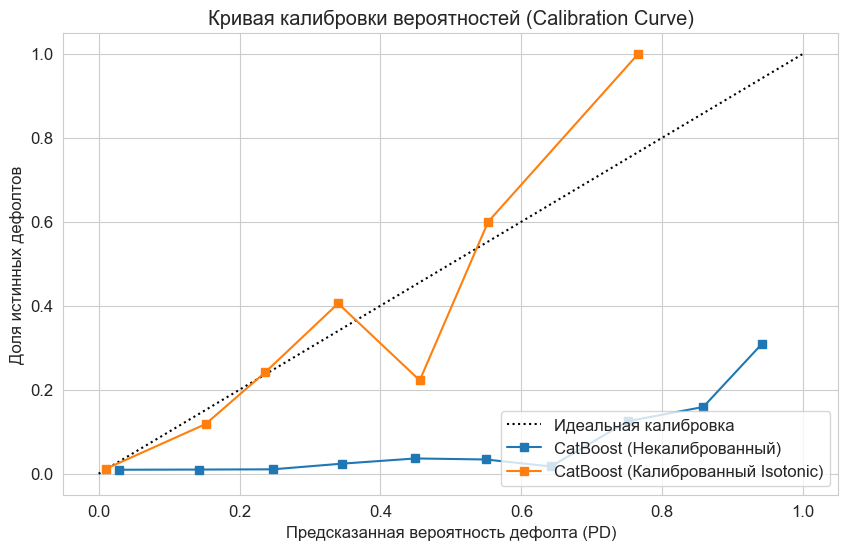

In [28]:
# Калибровка наилучшей модели (выберем CatBoost как пример устойчивой модели)
base_model = cb.CatBoostClassifier(auto_class_weights='Balanced', random_state=42, verbose=0)

# Изотоническая калибровка на кросс-валидации
calibrated_model = CalibratedClassifierCV(estimator=base_model, method='isotonic', cv=5)
calibrated_model.fit(X_train, y_train)

# Прогнозы до и после калибровки
cb_model.fit(X_train, y_train)
proba_uncalibrated = cb_model.predict_proba(X_test)[:, 1]
proba_calibrated = calibrated_model.predict_proba(X_test)[:, 1]

# Оценка Brier Score
print(f"Brier Score до калибровки: {np.mean((y_test - proba_uncalibrated) ** 2):.4f}")
print(f"Brier Score после калибровки: {np.mean((y_test - proba_calibrated) ** 2):.4f}")

# Построение графиков калибровки
fraction_of_positives_uncal, mean_predicted_value_uncal = calibration_curve(y_test, proba_uncalibrated, n_bins=10)
fraction_of_positives_cal, mean_predicted_value_cal = calibration_curve(y_test, proba_calibrated, n_bins=10)

plt.figure(figsize=(10, 6))
plt.plot([0, 1], [0, 1], "k:", label="Идеальная калибровка")
plt.plot(mean_predicted_value_uncal, fraction_of_positives_uncal, "s-", label="CatBoost (Некалиброванный)")
plt.plot(mean_predicted_value_cal, fraction_of_positives_cal, "s-", label="CatBoost (Калиброванный Isotonic)")
plt.ylabel("Доля истинных дефолтов")
plt.xlabel("Предсказанная вероятность дефолта (PD)")
plt.title("Кривая калибровки вероятностей (Calibration Curve)")
plt.legend(loc="lower right")
plt.show()

Интерпретация результатов через SHAP

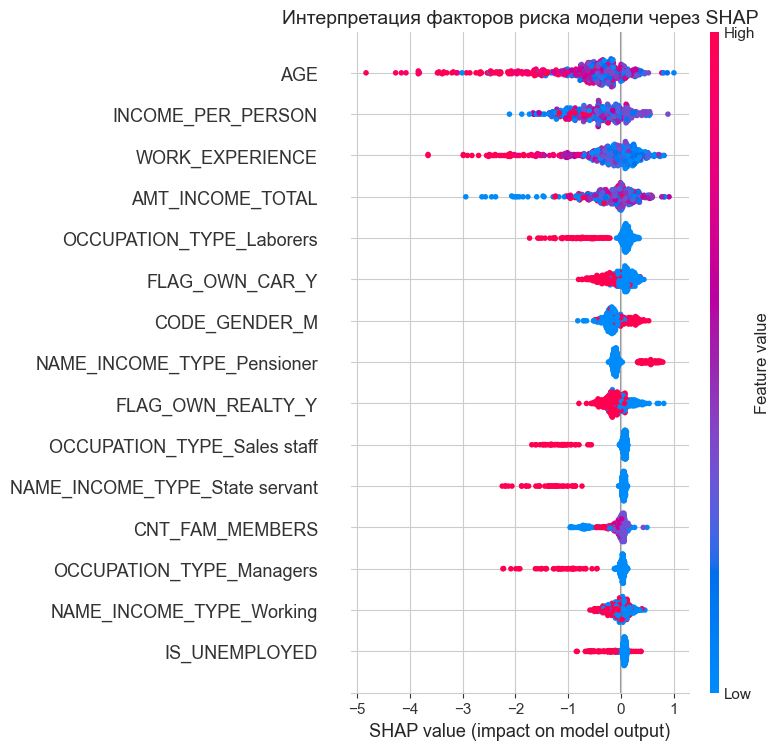

In [29]:
# Инициализация SHAP-эксплейнера для CatBoost
explainer = shap.TreeExplainer(cb_model)
# Расчет SHAP значений для подмножества тестовой выборки для ускорения
X_test_sample = X_test.sample(500, random_state=42)
shap_values = explainer(X_test_sample)

plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values, X_test_sample, max_display=15, show=False)
plt.title("Интерпретация факторов риска модели через SHAP", fontsize=14)
plt.show()

### Часть 5. 

Вариант А — Марковская матрица переходных вероятностей

Марковская матрица переходных вероятностей кредитных статусов:
NEXT_STATE       0.0       1.0       2.0
STATE                                   
0           0.992148  0.007595  0.000258
1           0.629412  0.317780  0.052808
2           0.185829  0.051805  0.762366


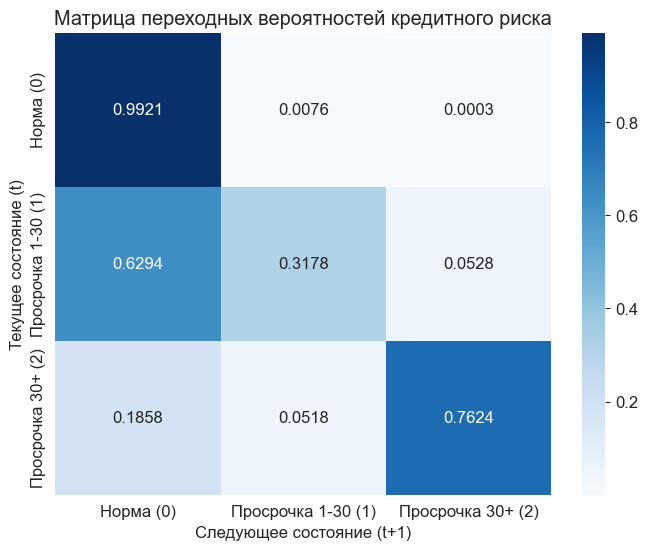

In [30]:
# Определение макро-состояний риска на базе кредитной истории
# Объединяем стабильные и технические статусы ('X', 'C', '0') в единое состояние 0
def соmap_status_to_state(status):
    if status in ['X', 'C', '0']:
        return 0  # Обслужен / Нет долга / Своевременно
    elif status == '1':
        return 1  # Просрочка 1-30 дней
    else:
        return 2  # Просрочка 30+ дней (ухудшение / дефолт)

crd['STATE'] = crd['STATUS'].apply(соmap_status_to_state)

# Сортировка по клиентам и месяцам для последовательного анализа
crd_sorted = crd.sort_values(by=['ID', 'MONTHS_BALANCE'])

# Формирование следующего состояния с помощью сдвига
crd_sorted['NEXT_STATE'] = crd_sorted.groupby('ID')['STATE'].shift(-1)

# Удаление пропусков (последний месяц наблюдения для каждого ID)
markov_pairs = crd_sorted.dropna(subset=['NEXT_STATE'])

# Построение матрицы сопряженности
transition_matrix = pd.crosstab(markov_pairs['STATE'], markov_pairs['NEXT_STATE'], normalize='index')

print("Марковская матрица переходных вероятностей кредитных статусов:")
print(transition_matrix)

# Отрисовка матрицы переходов
plt.figure(figsize=(8, 6))
sns.heatmap(transition_matrix, annot=True, cmap='Blues', fmt='.4f',
            xticklabels=['Норма (0)', 'Просрочка 1-30 (1)', 'Просрочка 30+ (2)'],
            yticklabels=['Норма (0)', 'Просрочка 1-30 (1)', 'Просрочка 30+ (2)'])
plt.title('Матрица переходных вероятностей кредитного риска')
plt.xlabel('Следующее состояние (t+1)')
plt.ylabel('Текущее состояние (t)')
plt.show()


Вариант Б — Динамическая ML-модель с лаговыми признаками

In [31]:
# Создание лаговых признаков (история состояний)
crd_sorted['PREV_STATE_1'] = crd_sorted.groupby('ID')['STATE'].shift(1)
crd_sorted['PREV_STATE_2'] = crd_sorted.groupby('ID')['STATE'].shift(2)

# Целевая переменная: перейдет ли клиент в тяжелую просрочку (2) на следующем шаге
crd_sorted['TARGET_ROLL_FORWARD'] = (crd_sorted['NEXT_STATE'] == 2).astype(int)

# Удаляем пропуски в лагах и таргете
dynamic_crd = crd_sorted.dropna(subset=['PREV_STATE_1', 'PREV_STATE_2', 'NEXT_STATE'])

# Берем последнее доступное наблюдение для каждого клиента для интеграции с анкетой
dynamic_crd_latest = dynamic_crd.groupby('ID').last().reset_index()

# Объединяем с анкетными данными клиентов
df_task2 = app.merge(dynamic_crd_latest[['ID', 'PREV_STATE_1', 'PREV_STATE_2', 'TARGET_ROLL_FORWARD']], on='ID', how='inner')

# Кодирование категориальных переменных
df_task2 = pd.get_dummies(df_task2, columns=categorical_cols, drop_first=True)

# Формирование обучающей выборки
exclude_cols_t2 = ['ID', 'TARGET_ROLL_FORWARD', 'DAYS_BIRTH', 'DAYS_EMPLOYED']
feature_cols_t2 = [col for col in df_task2.columns if col not in exclude_cols_t2]

X_t2 = df_task2[feature_cols_t2]
y_t2 = df_task2['TARGET_ROLL_FORWARD']

X_train_t2, X_test_t2, y_train_t2, y_test_t2 = train_test_split(X_t2, y_t2, test_size=0.3, random_state=42, stratify=y_t2)

# Обучение прогнозной модели динамики риска
rf_dynamic = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1)
rf_dynamic.fit(X_train_t2, y_train_t2)

print("Качество динамической модели прогнозирования ухудшения статуса (Roll-Forward):")
evaluate_scoring_model("Dynamic Random Forest", y_test_t2, rf_dynamic.predict(X_test_t2), rf_dynamic.predict_proba(X_test_t2)[:, 1])


Качество динамической модели прогнозирования ухудшения статуса (Roll-Forward):
--- Dynamic Random Forest ---
ROC-AUC (Разделяющая способность):    0.9826
PR-AUC (Качество при дисбалансе):     0.6853
KS Statistic (Статистика КC):         0.9624
Brier Score (Точность вероятности):   0.0016
Recall (Полнота по дефолтам):         0.5312
Precision (Точность по дефолтам):      0.4857



0.9826344665425688

### Часть 6. Survival Analysis

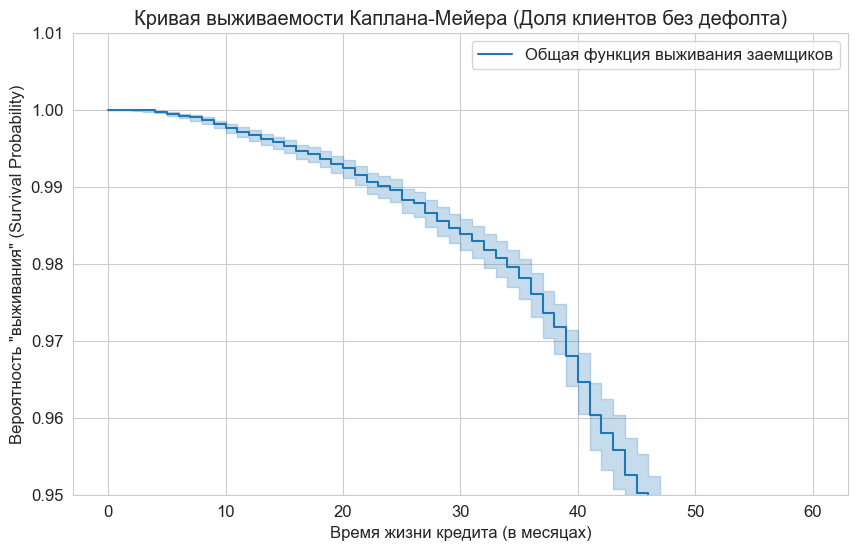

In [32]:
# Расчет параметров для Анализа выживаемости (Survival Analysis)
# Находим месяц открытия кредита (первое появление заемщика) и продолжительность наблюдения
survival_calc = crd.groupby('ID').agg(
    observed_months=('MONTHS_BALANCE', lambda x: abs(x.min()) - abs(x.max())),
    is_default=('IS_DEFAULT', 'max')
).reset_index()

# Корректировка нулевой продолжительности (минимум 1 месяц наблюдения)
survival_calc.loc[survival_calc['observed_months'] == 0, 'observed_months'] = 1

# Объединяем со статической анкетой
df_survival = app.merge(survival_calc, on='ID', how='inner')

# 1. Непараметрический анализ: Модель Каплана-Мейера
kmf = KaplanMeierFitter()
kmf.fit(durations=df_survival['observed_months'], event_observed=df_survival['is_default'], label='Общая функция выживания заемщиков')

# Визуализация кривой дожития кредитного портфеля
plt.figure(figsize=(10, 6))
kmf.plot_survival_function()
plt.title('Кривая выживаемости Каплана-Мейера (Доля клиентов без дефолта)')
plt.xlabel('Время жизни кредита (в месяцах)')
plt.ylabel('Вероятность "выживания" (Survival Probability)')
plt.ylim(0.95, 1.01) # Масштабируем из-за низкого уровня дефолтов
plt.grid(True)
plt.show()

### Часть 7. Регрессия пропорциональных рисков Кокса

Результаты регрессии пропорциональных рисков Кокса:


<lifelines.CoxPHFitter: fitted with 36457 total observations, 35841 right-censored observations>
             duration col = 'observed_months'
                event col = 'is_default'
      baseline estimation = breslow
   number of observations = 36457
number of events observed = 616
   partial log-likelihood = -5357.96
         time fit was run = 2026-10-21 14:08:36 UTC

---
                  coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                         
AGE              -0.01      0.99      0.00           -0.02           -0.01                0.98                0.99
WORK_EXPERIENCE  -0.05      0.95      0.01           -0.07           -0.04                0.93                0.96
AMT_INCOME_TOTAL -0.00      1.00      0.00           -0.00            0.00                1.00                1.00
CNT_FAM_MEMBERS  -0.10      0.91      0.05           -0.19           -0.01                0.82                0.99

                  cmp to     z      p  -log2(p)
covariate                                      
AGE                 0.00 -3.87 <0.005     13.14
WORK_EXPERIENCE     0.00 -6.44 <0.005     32.93
AMT_INCOME_TOTAL    0.00 -0.33   0.74      0.44
CNT_FAM_MEMBERS     0.00 -2.07   0.04      4.70
---
Concordance = 0.58
Partial AIC = 10723.92
log-likelihood ratio test = 64.21 on 4 df
-log2(p) of ll-ratio test = 41.27

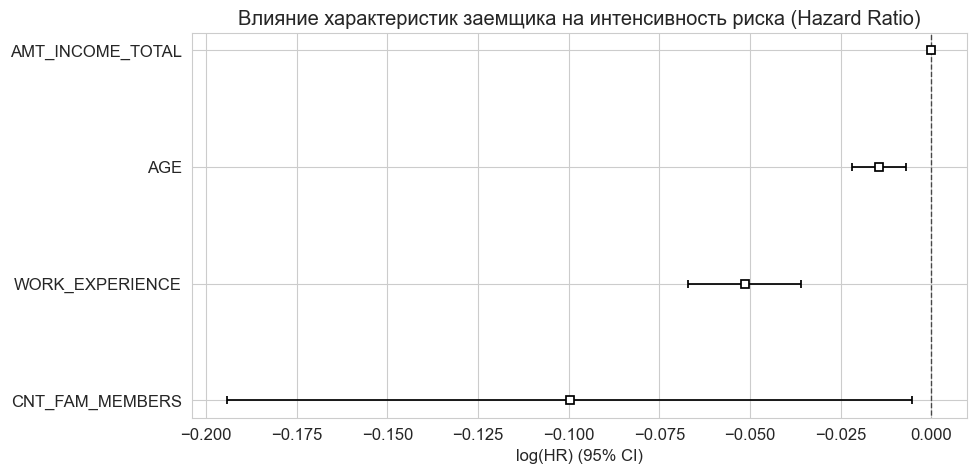

In [33]:
# 2. Полупараметрический анализ: Модель Кокса (Cox PH)
# Выбираем ключевые непрерывные макрофакторы для оценки рисков
survival_features = ['observed_months', 'is_default', 'AGE', 'WORK_EXPERIENCE', 'AMT_INCOME_TOTAL', 'CNT_FAM_MEMBERS']
df_cox = df_survival[survival_features]

# Обучение модели Кокса
cph = CoxPHFitter()
cph.fit(df_cox, duration_col='observed_months', event_col='is_default')

# Вывод результатов и коэффициентов отношения рисков (Hazard Ratio)
print("Результаты регрессии пропорциональных рисков Кокса:")
cph.print_summary()

# Визуализация влияния факторов на интенсивность риска дефолта
plt.figure(figsize=(10, 5))
cph.plot()
plt.title("Влияние характеристик заемщика на интенсивность риска (Hazard Ratio)")
plt.show()